# Quantum Fourier Transform (QFT)
### Fourier analysis of 2^N amplitudes with O(N^2) gates in NVIDIA CUDA-Q
*Notebook 8 of 8 - CUDA-Q Quantum Algorithm Benchmarking Suite*

This notebook builds the QFT circuit in CUDA-Q, applies it to an input state of your choice, compares the resulting amplitudes and measured bitstring probabilities with the exact mathematical result (NumPy FFT), and benchmarks time and memory on the selected backend.

**How to use this notebook:** run all cells from top to bottom (*Kernel -> Restart & Run All*).
Change parameters **only in Section 3**; every later cell reads them from there. The default
configuration runs immediately on a laptop CPU and much faster on an NVIDIA GPU.

| Section | Content |
|---|---|
| 1 | Problem statement and mathematical explanation |
| 2 | Import libraries (with installation instructions) |
| 3 | Input parameters - **the only cell you need to edit** |
| 4 | Example inputs |
| 5 | Benchmark utilities and backend initialization |
| 6 | Expected output (computed *before* running the quantum circuit) |
| 7 | Quantum circuit generation and visualization |
| 8 | Execution with live memory monitoring |
| 9 | Results and visualization |
| 10 | Final benchmark report |

---
## Section 1 - Problem statement and mathematical explanation

### What problem does the algorithm solve?
The QFT computes the **discrete Fourier transform of the $M = 2^N$ amplitudes** of an $N$-qubit state.
For a computational basis state $|x\rangle$ ($x$ is the integer written by the qubits, **qubit 0 = most
significant bit**):

$$\mathrm{QFT}\,|x\rangle = \frac{1}{\sqrt{M}} \sum_{y=0}^{M-1} e^{2\pi i\,xy/M}\,|y\rangle ,$$

and by linearity a general state $|\psi\rangle = \sum_x \alpha_x |x\rangle$ is mapped to
$\sum_y \beta_y |y\rangle$ with $\beta_y = \frac{1}{\sqrt{M}}\sum_x \alpha_x\, e^{2\pi i\,xy/M}$
(exactly NumPy's `np.fft.ifft(alpha, norm="ortho")`).

### Why is this problem important?
The QFT is the engine of the most important quantum algorithms: **Shor's factoring** (period finding),
**quantum phase estimation** (chemistry, HHL linear systems), quantum arithmetic and hidden-subgroup problems.
It turns *periodicity* hidden in amplitudes into peaks that a measurement can reveal.

### What is the classical approach?
The Fast Fourier Transform (FFT) of $M$ numbers costs $O(M \log M) = O(N\,2^N)$ operations and must store all
$2^N$ numbers.

### How does the quantum algorithm solve it?
The QFT output factorises into single-qubit states (product formula):

$$\mathrm{QFT}\,|x\rangle = \bigotimes_{l=1}^{N} \frac{|0\rangle + e^{2\pi i\, x / 2^{l}}\,|1\rangle}{\sqrt{2}} ,$$

which is built from only $N$ Hadamard gates, $N(N-1)/2$ controlled phase rotations
$R_k = \begin{pmatrix}1 & 0\\ 0 & e^{2\pi i/2^k}\end{pmatrix}$ and $\lfloor N/2\rfloor$ SWAPs:
**$O(N^2)$ gates** instead of $O(N 2^N)$ arithmetic operations. Qubit $j$ receives a Hadamard followed by
controlled rotations $R_2, R_3, \dots$ from the less significant qubits; the final SWAPs reverse the qubit order.

**Important caveat:** the result lives in the *amplitudes*. A measurement returns a single bitstring $y$ with
probability $P(y) = |\beta_y|^2$; reading all $2^N$ amplitudes would need exponentially many shots. The QFT is
useful when the answer is a **few large peaks**, as in period finding.

### Measurement
Measuring all qubits in the $Z$ basis samples $y$ with probability $|\beta_y|^2$. The distribution is **not
always uniform**: it is uniform only for a basis-state input (all $|\beta_y| = 1/\sqrt{M}$, information sits in
the phases). A periodic input with period $r$ produces peaks at multiples of $M/r$.

### What is the expected solution?
Default input: the periodic state $|\psi\rangle = \sqrt{r/M}\sum_{j}|j\,r + o\rangle$ with period $r = 8$ and
offset $o = 3$ on $N = 15$ qubits. Its QFT is

$$\mathrm{QFT}|\psi\rangle = \frac{1}{\sqrt{r}}\sum_{m=0}^{r-1} e^{2\pi i\, o\, m / r}\,|m\,M/r\rangle ,$$

i.e. **8 peaks** at $y = 0, 4096, 8192, \dots, 28672$, each with probability $1/8$ and phase $2\pi\cdot 3m/8$.

---
## Section 2 - Import libraries

All quantum code uses **NVIDIA CUDA-Q** (`cudaq`). The other libraries are standard scientific Python.

**Installation** (Linux x86_64/aarch64 with or without an NVIDIA GPU, or macOS on Apple silicon for CPU-only simulation):

```bash
python3 -m venv cudaq-env && source cudaq-env/bin/activate     # Python >= 3.11
pip install --upgrade pip
pip install cudaq numpy scipy matplotlib psutil nvidia-ml-py jupyter
```

* `pip install cudaq` detects your CUDA driver and installs the matching CUDA-Q build (CUDA 12.x or 13.x).
  A GPU is **not** required: CPU simulators are always available.
* `nvidia-ml-py` provides NVML bindings used for GPU memory monitoring (optional on CPU-only machines).
* Multi-GPU / multi-node runs additionally need MPI; see the README of this repository.

The next cell imports everything, prints the versions found and warns about incompatible versions.

In [1]:
# ---------------------------------------------------------------------------------
# Section 2 - Import libraries and check versions
# ---------------------------------------------------------------------------------
import os, sys, re, json, math, time, socket, platform      # standard library: files, timing, system info
import threading, subprocess, tempfile, datetime            # standard library: live memory monitor + report
import warnings                                             # used to hide two harmless CUDA-Q notices

# CUDA-Q 0.16 prints two informational warnings when imported: a "preview" notice for the
# bundled cudaq-logical package and a notice that sample/observe will change in a FUTURE
# release. Neither affects this notebook, so exactly these two messages are hidden.
warnings.filterwarnings("ignore", message=".*cudaq-logical is in preview.*")
warnings.filterwarnings("ignore", message=".*algorithmic primitives will change.*")

_missing = []                                               # collect missing packages for one clear message
try:
    import numpy as np                                      # arrays, linear algebra, random numbers
except ImportError:
    _missing.append("numpy")
try:
    import matplotlib                                       # plotting library
    import matplotlib.pyplot as plt                         # pyplot interface for figures
except ImportError:
    _missing.append("matplotlib")
try:
    import scipy                                            # scientific computing (optimizers, linear algebra)
    pass
except ImportError:
    _missing.append("scipy")
try:
    import psutil                                           # host RAM monitoring
except ImportError:
    _missing.append("psutil")
try:
    import cudaq                                            # NVIDIA CUDA-Q: kernels, simulators, QPU targets
except ImportError:
    _missing.append("cudaq")
if _missing:
    raise ImportError(f"Missing packages: {_missing}. Install them with:\n"
                      f"    pip install {' '.join(_missing)} nvidia-ml-py\n"
                      "CUDA-Q needs Linux (x86_64/aarch64) or macOS on Apple silicon (CPU only); see README.md.")

try:
    import pynvml                                           # NVIDIA Management Library bindings (GPU memory)
    HAVE_NVML = True
except ImportError:                                         # optional: only needed for GPU monitoring
    pynvml, HAVE_NVML = None, False

try:                                                        # live display inside Jupyter
    from IPython import get_ipython
    from IPython.display import display, Pretty
    _IN_JUPYTER = get_ipython() is not None and "IPKernelApp" in get_ipython().config
except Exception:                                           # running as a plain Python script
    display, Pretty, _IN_JUPYTER = None, None, False

# ---- Version report and compatibility check ----------------------------------------
_match = re.search(r"(\d+)\.(\d+)\.(\d+)", cudaq.__version__)
CUDAQ_VERSION = ".".join(_match.groups()) if _match else cudaq.__version__
_cudaq_tuple = tuple(int(x) for x in _match.groups()) if _match else (0, 0, 0)
print(f"Python      : {platform.python_version()} ({platform.system()} {platform.machine()})")
print(f"CUDA-Q      : {CUDAQ_VERSION}")
print(f"NumPy       : {np.__version__}")
print(f"SciPy       : {scipy.__version__}")
print(f"Matplotlib  : {matplotlib.__version__}")
print(f"psutil      : {psutil.__version__}")
print(f"nvidia-ml-py: {'installed' if HAVE_NVML else 'NOT installed (GPU memory monitoring disabled: pip install nvidia-ml-py)'}")
print(f"GPUs visible to CUDA-Q: {cudaq.num_available_gpus()}")
if sys.version_info < (3, 11):
    print("WARNING: CUDA-Q 0.16 wheels require Python >= 3.11.")
if _cudaq_tuple < (0, 12, 0):
    print("WARNING: this notebook was written and tested with CUDA-Q 0.16.0; versions older than 0.12 "
          "use a different operator API and are not supported. Upgrade with: pip install -U cudaq")
elif _cudaq_tuple != (0, 16, 0):
    print("Note: tested with CUDA-Q 0.16.0. Other versions should work; if an API error appears, "
          "compare with the README's 'Known limitations'.")

# ---------------------------------------------------------------------------------
# Plot style used by every figure: colour-blind-safe palette, hairline grid, one y-axis per chart
# ---------------------------------------------------------------------------------
# Categorical colours in a FIXED order (validated for colour-vision deficiency).
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, AQUA = SERIES_COLORS[0], SERIES_COLORS[1], SERIES_COLORS[2]
INK, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"   # text colours
GRID_COLOR, AXIS_COLOR, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"  # chart chrome
GOOD, CRITICAL = "#0ca30c", "#d03b3b"                                # reserved status colours
SEQUENTIAL_BLUE = matplotlib.colors.LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])          # magnitude
DIVERGING_BLUE_RED = matplotlib.colors.LinearSegmentedColormap.from_list(
    "div_blue_red", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#a32b2b"])      # signed values


def apply_plot_style():
    """Consistent, quiet chart style for every figure in this notebook."""
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "axes.edgecolor": AXIS_COLOR, "axes.labelcolor": INK_SECONDARY, "axes.titlecolor": INK,
        "text.color": INK, "xtick.color": AXIS_COLOR, "ytick.color": AXIS_COLOR,
        "xtick.labelcolor": INK_SECONDARY, "ytick.labelcolor": INK_SECONDARY,
        "axes.grid": True, "grid.color": GRID_COLOR, "grid.linewidth": 0.8, "grid.linestyle": "-",
        "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
        "axes.prop_cycle": matplotlib.cycler(color=SERIES_COLORS),
        "lines.linewidth": 2.0, "lines.solid_capstyle": "round", "lines.markersize": 6,
        "legend.frameon": False, "font.size": 10, "axes.titlesize": 11, "figure.dpi": 100,
    })


apply_plot_style()

Python      : 3.13.18 (Linux x86_64)
CUDA-Q      : 0.16.0
NumPy       : 2.5.4
SciPy       : 1.18.1
Matplotlib  : 3.11.2
psutil      : 7.2.2
nvidia-ml-py: installed
GPUs visible to CUDA-Q: 0


---
## Section 3 - Input parameters

This is the **only cell you need to edit**. Every later cell reads these variables.

In [2]:
# =====================================================================================
# Section 3 - INPUT PARAMETERS  (edit only this cell, then re-run the notebook)
# =====================================================================================

# ---- Problem definition ---------------------------------------------------------------
N_QUBITS = 15                    # number of qubits; the QFT acts on 2**N_QUBITS amplitudes
INITIAL_STATE = "periodic"       # "periodic" | "basis" | "random" | "custom"  (see Section 4)
PERIOD = 8                       # "periodic": spacing r of the non-zero amplitudes (power of 2 -> gate-prepared, any N)
OFFSET = 3                       # "periodic": index of the first non-zero amplitude, 0 <= OFFSET < PERIOD
BASIS_STATE = 5                  # "basis": integer x with 0 <= x < 2**N_QUBITS (qubit 0 = most significant bit)
CUSTOM_AMPLITUDES = None         # "custom": list / NumPy array of 2**N_QUBITS complex amplitudes (normalised for you)

# ---- Analysis -----------------------------------------------------------------------------
AMPLITUDE_ANALYSIS_MAX_QUBITS = 24   # read back the full state vector (amplitudes, fidelity) only up to this N
TOP_K = 16                       # number of largest amplitudes / most frequent bitstrings listed

# ---- Backend and simulation method ---------------------------------------------------
BACKEND = "auto"                 # "auto" | "cpu" | "gpu" | "multi-gpu" | "hardware"
SIMULATION_METHOD = "statevector"   # this notebook supports: "statevector" | "mps" | "tensornet" | "density_matrix"
GPU_PRECISION = "fp64"            # "fp64" (16 B/amplitude) | "fp32" (8 B/amplitude, half the memory)
HARDWARE_PROVIDER = "quantinuum"  # only for BACKEND="hardware": "quantinuum", "ionq", "oqc", "anyon", "infleqtion", ...
HARDWARE_EMULATE = True           # True: local emulation (no account, no cost); False: real QPU (credentials needed)
HARDWARE_MACHINE = None           # provider device name, e.g. "H2-1E"; None = provider default

# ---- Shots and reproducibility --------------------------------------------------------
SHOTS = 4000                       # measurement repetitions; statistical error ~ 1/sqrt(SHOTS)
SEED = 42                         # fixes NumPy and CUDA-Q random numbers -> reproducible results

# ---- Memory monitoring ----------------------------------------------------------------
LIVE_MEMORY_DISPLAY = True        # live RAM / GPU memory line while the execution cell runs
MEMORY_SAMPLE_INTERVAL_S = 0.25   # sampling period in seconds (smaller = finer timeline)
MEMORY_SAFETY_FRACTION = 0.8      # refuse runs whose state needs more than 80% of free memory

# ---- Circuit drawing, export and report ---------------------------------------------------
DRAW_QUBITS = 10                  # qubits shown in the circuit drawing (maximum 10)
EXPORT_CIRCUIT = True             # save drawing + full circuit to EXPORT_DIR
EXPORT_FORMATS = ["txt", "png", "qir"]   # "txt", "png" (drawing), "qir", "qasm" (full circuit)
EXPORT_DIR = "exports/qft"     # output folder (created automatically)
SAVE_REPORT = True                # save the final benchmark report (JSON) and figure (PNG)

#### What every parameter means and what happens when you change it

| Parameter | Meaning | Effect of changing it |
|---|---|---|
| `N_QUBITS` | Number of qubits $N$; the transform acts on $M = 2^N$ amplitudes. | The circuit grows only like $N^2$ gates, but the simulated state doubles in memory with every qubit (16 x 2^N bytes in fp64): 15 -> 0.5 MB, 30 -> 17 GB, 40 -> 17.6 TB (use `"mps"`). |
| `INITIAL_STATE` | Input state: `"periodic"`, `"basis"`, `"random"` or `"custom"`. | Changes the output distribution: periodic -> sharp peaks; basis -> flat distribution with a linear phase ramp; random -> irregular. `"random"`/`"custom"` and non-power-of-2 periods use amplitude encoding (simulators only, N <= 24). |
| `PERIOD` / `OFFSET` | Period $r$ and offset $o$ of the periodic input. | Peaks appear at multiples of $M/r$. A power of 2 gives exactly $r$ sharp peaks; other values spread probability around the peaks ("leakage"), as in Shor's algorithm. |
| `BASIS_STATE` | Integer $x$ for the basis-state input. | Only the phases of the output change with $x$; all probabilities stay $1/M$. |
| `CUSTOM_AMPLITUDES` | Your own state vector (index = integer with qubit 0 as most significant bit). | Must have exactly $2^N$ entries; it is normalised automatically. |
| `AMPLITUDE_ANALYSIS_MAX_QUBITS` | Largest N for which the full state vector is copied back for amplitude comparison. | Each copy needs 16 x 2^N bytes of host RAM; above this size only measured counts are compared (with an analytic expectation for gate-prepared inputs). |
| `TOP_K` | Rows shown in the amplitude and bitstring tables. | Display only. |
| `BACKEND` | Where the circuit runs: `"auto"` (NVIDIA GPU if CUDA-Q sees one, otherwise CPU), `"cpu"`, `"gpu"`, `"multi-gpu"`, `"hardware"`. | GPU state-vector simulation is typically 10-1000x faster than CPU for N >= 20 and is limited by GPU memory. `"multi-gpu"` pools the memory of several GPUs (launch with MPI, see README). `"hardware"` sends the circuit to a quantum computer provider (sampling only). |
| `SIMULATION_METHOD` | How the quantum state is stored (the allowed values for this notebook are listed in the input cell). `"statevector"`: all 2^N amplitudes, exact. `"mps"`: matrix product state, compressed (GPU). `"tensornet"`: exact tensor-network contraction (GPU). `"density_matrix"`: 4^N entries, supports noise (CPU). | Changes memory and run time: state vector needs 16 x 2^N bytes (fp64), density matrix 16 x 4^N bytes, MPS grows with entanglement instead of with N. An unsupported combination stops with an explanation. |
| `GPU_PRECISION` | `"fp64"` (16 bytes per amplitude) or `"fp32"` (8 bytes). GPU targets only; CPU targets always use fp64. | fp32 halves memory (one more qubit fits) and is faster, with ~1e-7 relative precision instead of ~1e-16. |
| `HARDWARE_PROVIDER` / `HARDWARE_EMULATE` / `HARDWARE_MACHINE` | Used only when `BACKEND="hardware"`: provider target (`"quantinuum"`, `"ionq"`, `"oqc"`, `"anyon"`, `"infleqtion"`, ...), local emulation switch, device name. | `HARDWARE_EMULATE=True` runs the provider's compilation flow locally with no account and no cost. `False` submits real jobs: needs credentials, may cost money, waits in a queue. |
| `SHOTS` | Number of times the circuit is executed and measured. | Statistical error of every measured probability shrinks like 1/sqrt(SHOTS). On simulators extra shots are cheap; on hardware cost grows linearly. |
| `SEED` | Random seed for NumPy and CUDA-Q's shot sampler. | Same seed gives identical results on re-run; change it to see statistical fluctuations. |
| `LIVE_MEMORY_DISPLAY` / `MEMORY_SAMPLE_INTERVAL_S` | Live RAM/GPU memory line during execution; sampling period in seconds. | Smaller intervals give a finer memory timeline; peaks shorter than the interval can be missed. |
| `MEMORY_SAFETY_FRACTION` | The run is refused if the quantum state would need more than this fraction of the free memory. | Raise it (e.g. 0.95) if you know the run fits; lower it to protect other work on the machine. |
| `DRAW_QUBITS` | Number of qubits used for the circuit **drawing** (at most 10). | Only changes the picture; execution always uses the full number of qubits. |
| `EXPORT_CIRCUIT` / `EXPORT_FORMATS` / `EXPORT_DIR` / `SAVE_REPORT` | Save the drawing (`"txt"`, `"png"`), the full circuit (`"qir"`, `"qasm"`), the report (JSON) and final figure (PNG) to `EXPORT_DIR`. | Set `EXPORT_CIRCUIT=False` / `SAVE_REPORT=False` to write nothing to disk. |

---
## Section 4 - Example inputs

**Default example (runs as is):** `INITIAL_STATE = "periodic"`, `PERIOD = 8`, `OFFSET = 3`, `N_QUBITS = 15`.
Because the period is a power of two, the state is prepared with plain gates (Hadamards on the 12 most
significant qubits, $X$ gates writing the offset into the 3 least significant ones), so the example scales to
any $N$ and runs on every backend.

| Goal | Setting in Section 3 | Expected QFT output |
|---|---|---|
| Sharp peaks (default) | `INITIAL_STATE="periodic"`, `PERIOD=8`, `OFFSET=3` | 8 peaks of probability 1/8 at multiples of $2^N/8$ |
| Leakage (like Shor) | `PERIOD=6`, `OFFSET=1` | 6 clusters around multiples of $2^N/6$ (amplitude encoding) |
| Basis state | `INITIAL_STATE="basis"`, `BASIS_STATE=5` | flat distribution, phases $e^{2\pi i\,5y/M}$ |
| Random state | `INITIAL_STATE="random"` | irregular distribution; checks the transform on a generic state |
| Your own state | `INITIAL_STATE="custom"`, `CUSTOM_AMPLITUDES=[...]` | whatever its Fourier transform is |
| Large N | `N_QUBITS=30`, `BACKEND="gpu"` (or `SIMULATION_METHOD="mps"` for 40+) | same 8 peaks, now at multiples of $2^{27}$ |

The cell below builds the input state, checks it and plots its amplitudes.

Input state      : periodic state, period r = 8, offset o = 3
Qubits / amplitudes: 15 / 32,768
State preparation: X/H gates (works on every backend, any N)
Non-zero amplitudes: 4,096; first indices: [3, 11, 19, 27, 35, 43, 51, 59]


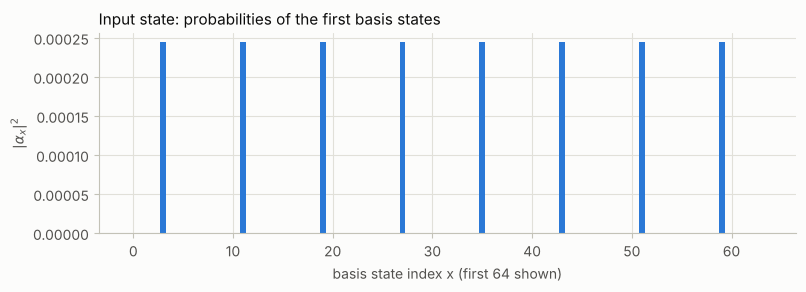

In [3]:
# ---------------------------------------------------------------------------------
# Section 4 - Build and validate the input state from the Section 3 inputs
# ---------------------------------------------------------------------------------
if not isinstance(N_QUBITS, (int, np.integer)) or N_QUBITS < 1:
    raise ValueError("N_QUBITS must be a positive integer.")
N_QUBITS = int(N_QUBITS)
M = 2 ** N_QUBITS                                                   # number of amplitudes
mode = str(INITIAL_STATE).strip().lower()
h_mask = [0] * N_QUBITS                                             # 1 -> Hadamard on that qubit (gate preparation)
x_mask = [0] * N_QUBITS                                             # 1 -> X gate on that qubit (gate preparation)
input_amplitudes = None                                             # full vector (only if small enough / needed)

def is_power_of_two(value):
    return value >= 1 and (value & (value - 1)) == 0

if mode == "basis":
    if not 0 <= int(BASIS_STATE) < M:
        raise ValueError(f"BASIS_STATE must satisfy 0 <= x < 2**{N_QUBITS}.")
    x_mask = [int(b) for b in format(int(BASIS_STATE), f"0{N_QUBITS}b")]   # qubit 0 = most significant bit
    preparation = "gates"
    description = f"basis state |{int(BASIS_STATE)}> = |{format(int(BASIS_STATE), f'0{N_QUBITS}b')}>"
elif mode == "periodic":
    r, o = int(PERIOD), int(OFFSET)
    if not 1 <= r <= M or not 0 <= o < r:
        raise ValueError(f"Need 1 <= PERIOD <= 2**N and 0 <= OFFSET < PERIOD (got PERIOD={r}, OFFSET={o}).")
    description = f"periodic state, period r = {r}, offset o = {o}"
    if is_power_of_two(r):                                          # x = j*r + o: low bits fixed, high bits uniform
        p = r.bit_length() - 1                                      # r = 2^p
        h_mask = [1] * (N_QUBITS - p) + [0] * p                     # uniform over the N-p most significant bits
        x_mask = [0] * (N_QUBITS - p) + ([int(b) for b in format(o, f"0{p}b")] if p > 0 else [])
        preparation = "gates"
    else:
        preparation = "amplitudes"
elif mode == "random":
    preparation = "amplitudes"
    description = f"random complex state (seed {SEED})"
elif mode == "custom":
    if CUSTOM_AMPLITUDES is None:
        raise ValueError("INITIAL_STATE='custom' needs CUSTOM_AMPLITUDES (a list of 2**N_QUBITS numbers).")
    preparation = "amplitudes"
    description = "custom amplitudes"
else:
    raise ValueError("INITIAL_STATE must be 'periodic', 'basis', 'random' or 'custom'.")

analyse_amplitudes = N_QUBITS <= int(AMPLITUDE_ANALYSIS_MAX_QUBITS)
if preparation == "amplitudes" and not analyse_amplitudes:
    raise ValueError(f"'{mode}' input needs all 2**{N_QUBITS} amplitudes in memory (amplitude encoding). Use "
                     f"N_QUBITS <= {AMPLITUDE_ANALYSIS_MAX_QUBITS}, a power-of-2 PERIOD or a basis state.")

if analyse_amplitudes or preparation == "amplitudes":               # explicit input vector, index = integer x
    if mode == "basis":
        input_amplitudes = np.zeros(M, dtype=complex)
        input_amplitudes[int(BASIS_STATE)] = 1.0
    elif mode == "periodic":
        input_amplitudes = np.zeros(M, dtype=complex)
        input_amplitudes[int(OFFSET)::int(PERIOD)] = 1.0
    elif mode == "random":
        rng = np.random.default_rng(SEED)
        input_amplitudes = rng.normal(size=M) + 1j * rng.normal(size=M)
    else:
        input_amplitudes = np.asarray(CUSTOM_AMPLITUDES, dtype=complex).ravel()
        if input_amplitudes.size != M:
            raise ValueError(f"CUSTOM_AMPLITUDES must contain 2**{N_QUBITS} = {M} numbers, got {input_amplitudes.size}.")
    norm = np.linalg.norm(input_amplitudes)
    if norm == 0:
        raise ValueError("The input vector is all zeros.")
    input_amplitudes = input_amplitudes / norm                       # quantum states have norm 1

print(f"Input state      : {description}")
print(f"Qubits / amplitudes: {N_QUBITS} / {M:,}")
print(f"State preparation: {'X/H gates (works on every backend, any N)' if preparation == 'gates' else 'amplitude encoding cudaq.qvector(vector) (simulators only)'}")
if input_amplitudes is not None:
    nonzero = np.flatnonzero(np.abs(input_amplitudes) > 1e-12)
    print(f"Non-zero amplitudes: {nonzero.size:,}; first indices: {nonzero[:8].tolist()}")
    fig, ax = plt.subplots(figsize=(9, 2.6))
    shown = slice(0, min(M, 64))                                    # first 64 indices are enough to see the pattern
    ax.bar(np.arange(M)[shown], np.abs(input_amplitudes[shown]) ** 2, width=0.6, color=BLUE)
    ax.set_xlabel("basis state index x (first 64 shown)")
    ax.set_ylabel(r"$|\alpha_x|^2$")
    ax.set_title("Input state: probabilities of the first basis states", loc="left")
    plt.show()

---
## Section 5 - Benchmark utilities and backend initialization

The first cell below defines helper functions shared by all eight notebooks (you do not need to edit it):

* **Backend selection** - translates `BACKEND` + `SIMULATION_METHOD` into a real CUDA-Q target and
  refuses combinations CUDA-Q does not support (for example MPS on a CPU) with an explanation.
* **Memory estimation** - exact formulas for the memory needed by the quantum state.
* **Live memory monitor** - a small separate process samples host RAM (`psutil`) and the memory of
  every NVIDIA GPU (NVML) while the execution cell runs.
* **Timing** - separates circuit construction, compilation and execution using CUDA-Q's built-in tracer.
* **Circuit drawing / export** and the **final benchmark report**.

The second cell activates the selected backend and checks that the problem fits into memory.

| Your choice | CUDA-Q target used | Notes |
|---|---|---|
| `cpu` + `statevector` | `qpp-cpu` | OpenMP state vector, fp64 |
| `cpu` + `density_matrix` | `density-matrix-cpu` | mixed states and noise, fp64, 4^N memory |
| `cpu` + `stabilizer` | `stim` | Clifford circuits + Pauli noise only (noise notebook) |
| `gpu` + `statevector` | `nvidia` (option fp32/fp64) | cuStateVec, one GPU |
| `gpu` + `trajectory` | `nvidia` + noise model | Monte-Carlo noise trajectories (noise notebook) |
| `gpu` + `mps` | `tensornet-mps` | cuTensorNet matrix product state |
| `gpu` + `tensornet` | `tensornet` | cuTensorNet exact contraction |
| `multi-gpu` + `statevector` | `nvidia` (option `mgpu,fp64`) | state vector split over GPUs; needs `mpiexec` |
| `multi-gpu` + `tensornet` | `tensornet` | contraction distributed over GPUs; needs `mpiexec` |
| `hardware` | provider target (`quantinuum`, `ionq`, ...) | sampling only; `emulate=True` runs locally |

In [4]:
# =====================================================================================
# BENCHMARK & MONITORING UTILITIES  (this cell is identical in all 8 notebooks)
# -------------------------------------------------------------------------------------
# You do not need to edit this cell. It defines helper functions used later:
#   resolve_backend()       -> turns BACKEND + SIMULATION_METHOD into a real CUDA-Q target
#   initialize_backend()    -> calls cudaq.set_target() safely
#   estimate_memory_bytes() -> memory needed to store the quantum state (exact formulas)
#   check_memory()          -> compares that requirement with free RAM / GPU memory
#   MemoryMonitor           -> live RAM + GPU memory monitoring during execution
#   profile_first_launch()  -> splits a kernel launch into construction/compilation/execution
#   measure_gate_time()     -> short calibration used for execution-time estimates
#   show_circuit()          -> prints a <=10-qubit circuit drawing and exports it
#   circuit_statistics()    -> gate counts/depth of the FULL circuit (no simulation needed)
#   show_report()           -> prints and saves the final benchmark report
# =====================================================================================

# ---------------------------------------------------------------------------------
# 1. Backend selection
# ---------------------------------------------------------------------------------
# (device, simulation method) -> (CUDA-Q target name, does the target accept fp32/fp64?)
# Only combinations that CUDA-Q actually ships are listed. Anything else raises a clear
# error instead of silently running on a different simulator.
_TARGET_TABLE = {
    ("cpu", "statevector"): ("qpp-cpu", False),             # OpenMP state vector (always fp64)
    ("cpu", "density_matrix"): ("density-matrix-cpu", False),  # exact mixed states (noise), fp64
    ("cpu", "stabilizer"): ("stim", False),                 # Clifford circuits + Pauli noise only
    ("gpu", "statevector"): ("nvidia", True),               # cuStateVec on one GPU
    ("gpu", "trajectory"): ("nvidia", True),                # cuStateVec + noise = Monte-Carlo trajectories
    ("gpu", "mps"): ("tensornet-mps", True),                # cuTensorNet matrix product state
    ("gpu", "tensornet"): ("tensornet", True),              # cuTensorNet exact tensor-network contraction
    ("multi-gpu", "statevector"): ("nvidia", True),         # one state vector split across GPUs (MPI)
    ("multi-gpu", "tensornet"): ("tensornet", True),        # contraction distributed across GPUs (MPI)
}

# Explanations for combinations CUDA-Q does not support (shown to the user on error).
_UNSUPPORTED_HINTS = {
    ("cpu", "mps"): "CUDA-Q's MPS simulator (target 'tensornet-mps') needs an NVIDIA GPU. "
                    "Use BACKEND='gpu', or SIMULATION_METHOD='statevector' on CPU.",
    ("cpu", "tensornet"): "CUDA-Q's tensor-network simulator (target 'tensornet') needs an NVIDIA GPU.",
    ("cpu", "trajectory"): "Trajectory-based noisy simulation runs on GPUs in CUDA-Q. On CPU use "
                           "'density_matrix' (exact, small N) or 'stabilizer' (Clifford circuits).",
    ("gpu", "density_matrix"): "CUDA-Q's density-matrix simulator is CPU-only ('density-matrix-cpu'). "
                               "On GPUs noisy circuits are simulated with 'trajectory'.",
    ("gpu", "stabilizer"): "The stabilizer simulator ('stim') is CPU-only. Use BACKEND='cpu'.",
    ("multi-gpu", "mps"): "The MPS simulator runs on a single GPU. Use BACKEND='gpu'.",
    ("multi-gpu", "density_matrix"): "The density-matrix simulator is CPU-only. Use BACKEND='cpu'.",
    ("multi-gpu", "stabilizer"): "The stabilizer simulator ('stim') is CPU-only. Use BACKEND='cpu'.",
    ("multi-gpu", "trajectory"): "Use BACKEND='gpu' for trajectory simulation in this notebook.",
}


def mpi_rank_info():
    """Return (rank, number_of_ranks). (0, 1) means a normal single-process run."""
    try:
        if cudaq.mpi.is_initialized():                       # CUDA-Q already started MPI
            return cudaq.mpi.rank(), cudaq.mpi.num_ranks()
    except Exception:                                        # cudaq.mpi may be unavailable
        pass
    # Common launcher environment variables (Open MPI, MPICH/Intel MPI, Slurm)
    for rank_var, size_var in (("OMPI_COMM_WORLD_RANK", "OMPI_COMM_WORLD_SIZE"),
                               ("PMI_RANK", "PMI_SIZE"), ("SLURM_PROCID", "SLURM_NTASKS")):
        if rank_var in os.environ:
            return int(os.environ[rank_var]), int(os.environ.get(size_var, "1"))
    return 0, 1


def resolve_backend(backend, method, precision, allowed_methods, hardware_provider=None,
                    hardware_emulate=True, hardware_machine=None):
    """Translate the user's BACKEND / SIMULATION_METHOD choice into a concrete CUDA-Q target.

    Nothing is changed in CUDA-Q here; we only validate and describe the choice.
    Raises ValueError / RuntimeError with an explanation for unsupported choices.
    """
    backend = str(backend).strip().lower()                   # tolerate "GPU", " cpu " ...
    requested = backend                                      # remember the user's original choice
    method = str(method).strip().lower()
    precision = str(precision).strip().lower()
    num_gpus = cudaq.num_available_gpus()                    # GPUs visible to CUDA-Q (0 on CPU-only machines)

    if backend == "auto":                                    # "auto": use a GPU if present, else the CPU
        backend = "gpu" if num_gpus > 0 else "cpu"
    if backend not in ("cpu", "gpu", "multi-gpu", "hardware"):
        raise ValueError(f"BACKEND must be 'auto', 'cpu', 'gpu', 'multi-gpu' or 'hardware', got {backend!r}")
    if precision not in ("fp32", "fp64"):
        raise ValueError(f"GPU_PRECISION must be 'fp32' or 'fp64', got {precision!r}")

    if backend == "hardware":                                # real QPU (or its local emulator)
        provider = str(hardware_provider).strip().lower()
        if not cudaq.has_target(provider):
            raise ValueError(f"CUDA-Q has no target named {provider!r}. "
                             f"Available targets: {sorted(t.name for t in cudaq.get_targets())}")
        kwargs = {}
        if hardware_emulate:
            kwargs["emulate"] = True                         # run locally, no credentials, no cost
        if hardware_machine:
            kwargs["machine"] = hardware_machine             # e.g. "H2-1E" for Quantinuum
        return {"backend_requested": requested, "device": "hardware", "method": "hardware",
                "target": provider, "kwargs": kwargs, "precision": "n/a", "num_gpus": num_gpus,
                "description": f"{provider} QPU " + ("(LOCAL EMULATION - no credentials, no cost)"
                                                     if hardware_emulate else "(REAL HARDWARE - needs credentials, may cost money)")}

    if method not in allowed_methods:                        # notebook-specific restriction
        raise ValueError(f"SIMULATION_METHOD={method!r} is not supported by this notebook. "
                         f"Choose one of {allowed_methods}.")
    if backend in ("gpu", "multi-gpu") and num_gpus == 0:    # never touch GPU targets without a GPU
        raise RuntimeError(f"BACKEND={backend!r} was requested but CUDA-Q sees no NVIDIA GPU "
                           "(cudaq.num_available_gpus() == 0). Check `nvidia-smi`, the driver and "
                           "the CUDA-Q CUDA variant (see README), or use BACKEND='cpu'.")
    key = (backend, method)
    if key not in _TARGET_TABLE:
        raise ValueError(_UNSUPPORTED_HINTS.get(key, f"Combination {key} is not supported by CUDA-Q."))
    target, takes_precision = _TARGET_TABLE[key]

    rank, size = mpi_rank_info()
    note = ""
    if backend == "multi-gpu" and method == "statevector":
        if size > 1:                                         # launched with mpiexec -> pool all GPUs
            option = f"mgpu,{precision}"
        else:                                                # plain Jupyter process: one rank = one GPU
            option = precision
            note = ("Multi-GPU state-vector pooling needs one MPI rank per GPU (see README: "
                    "`mpiexec -np <GPUs> python notebook.py`). This single process uses ONE GPU.")
    else:
        option = precision if takes_precision else ""
    kwargs = {"option": option} if option else {}
    return {"backend_requested": requested, "device": backend, "method": method, "target": target,
            "kwargs": kwargs, "precision": precision if takes_precision else "fp64",
            "num_gpus": num_gpus, "mpi_ranks": size,
            "description": f"{target}" + (f" (option={option})" if option else "") + (f" - {note}" if note else "")}


def initialize_backend(cfg, seed=None):
    """Activate the CUDA-Q target described by cfg (from resolve_backend) and seed its RNG."""
    if cfg["device"] == "multi-gpu" and cfg.get("mpi_ranks", 1) > 1 and not cudaq.mpi.is_initialized():
        cudaq.mpi.initialize()                               # required before using MPI-based targets
    cudaq.set_target(cfg["target"], **cfg["kwargs"])         # switch simulator / QPU
    if seed is not None:
        cudaq.set_random_seed(int(seed))                     # reproducible shot sampling
    return cudaq.get_target()


# ---------------------------------------------------------------------------------
# 2. Memory requirement estimates and availability checks
# ---------------------------------------------------------------------------------
def format_bytes(num_bytes):
    """Human-readable size. Works for astronomically large Python integers as well."""
    if num_bytes is None:
        return "n/a"
    if num_bytes >= 10**18:                                  # beyond exabytes: use powers of ten
        return f"10^{math.log10(num_bytes):.1f} bytes"
    for unit, scale in (("TB", 1e12), ("GB", 1e9), ("MB", 1e6), ("KB", 1e3)):
        if num_bytes >= scale:
            return f"{num_bytes / scale:.2f} {unit}"
    return f"{int(num_bytes)} B"


def estimate_memory_bytes(n_qubits, method, precision="fp64"):
    """Bytes needed to STORE the simulated quantum state (simulator workspace not included).

    statevector / trajectory : 2^N complex amplitudes (8 B each in fp32, 16 B in fp64)
    density_matrix           : 4^N complex entries (16 B each, fp64)
    mps                      : upper bound N * 2 * chi^2 amplitudes, chi = CUDAQ_MPS_MAX_BOND (default 64)
    stabilizer               : ~2N^2 bits (tiny)
    tensornet / hardware     : not predictable -> None
    """
    bytes_per_amplitude = 8 if precision == "fp32" else 16
    if method in ("statevector", "trajectory"):
        return (2 ** n_qubits) * bytes_per_amplitude
    if method == "density_matrix":
        return (4 ** n_qubits) * 16
    if method == "mps":
        chi = int(os.environ.get("CUDAQ_MPS_MAX_BOND", "64"))
        return n_qubits * 2 * chi * chi * bytes_per_amplitude
    if method == "stabilizer":
        return max(1, (2 * n_qubits * n_qubits) // 8)
    return None


def _nvml_gpu_memory():
    """List of (used_bytes, total_bytes, name) per GPU, or (None, reason) if NVML is unavailable."""
    if not HAVE_NVML:
        return None, "nvidia-ml-py (pynvml) is not installed"
    try:
        pynvml.nvmlInit()
        result = []
        for i in range(pynvml.nvmlDeviceGetCount()):
            handle = pynvml.nvmlDeviceGetHandleByIndex(i)
            info = pynvml.nvmlDeviceGetMemoryInfo(handle)
            name = pynvml.nvmlDeviceGetName(handle)
            result.append((info.used, info.total, name.decode() if isinstance(name, bytes) else name))
        return result, "NVML OK"
    except Exception as exc:                                 # no driver / no GPU
        return None, f"NVML unavailable ({type(exc).__name__}: {exc})"


def check_memory(required_bytes, cfg, safety_fraction=0.8, extra_copies=0):
    """Print required vs available memory and stop (MemoryError) if the run cannot fit.

    extra_copies: additional full copies of the state the notebook makes (e.g. get_state()
    returns a host copy of the state vector), added on top of the simulator's own copy.
    """
    if required_bytes is None:
        print("Memory requirement: cannot be predicted for this method (depends on circuit structure).")
        return None
    host_copy = extra_copies * required_bytes
    if cfg["device"] in ("gpu", "multi-gpu"):
        gpus, status = _nvml_gpu_memory()
        if gpus is None:
            print(f"GPU memory check skipped: {status}. Required (state only): {format_bytes(required_bytes)}")
            return None
        used_gpus = gpus if (cfg["device"] == "multi-gpu" and cfg.get("mpi_ranks", 1) > 1) else gpus[:1]
        available = sum(total - used for used, total, _ in used_gpus)
        where = f"free memory on {len(used_gpus)} GPU(s)"
    else:                                                    # CPU simulators and local emulators use host RAM
        available = psutil.virtual_memory().available
        where = "available host RAM"
        required_bytes = required_bytes + host_copy
        host_copy = 0
    print(f"Estimated memory for the quantum state : {format_bytes(required_bytes)}")
    if host_copy:
        print(f"Extra host RAM for state copies        : {format_bytes(host_copy)}")
    print(f"{where:<39}: {format_bytes(available)}  (safety limit {safety_fraction:.0%})")
    if required_bytes > safety_fraction * available:
        raise MemoryError(f"The state needs {format_bytes(required_bytes)} but only "
                          f"{format_bytes(available)} is {where.split(' on ')[0]} (limit {safety_fraction:.0%}). "
                          "Reduce the number of qubits, use fp32, an MPS/tensor-network method, more GPUs, "
                          "or raise MEMORY_SAFETY_FRACTION if you know the run fits.")
    print("Memory check: OK - the state fits within the safety limit.")
    return available


# ---------------------------------------------------------------------------------
# 3. Live memory monitor
# ---------------------------------------------------------------------------------
# Some CUDA-Q calls (for example cudaq.get_state) hold Python's global interpreter lock,
# which would freeze an ordinary Python thread. The sampler therefore runs as a small
# separate process that writes one JSON line per sample to a temporary file. A light
# thread in this notebook reads that file and refreshes the live display.
_SAMPLER_SCRIPT = r'''
import json, sys, time, psutil
pid, interval, path = int(sys.argv[1]), float(sys.argv[2]), sys.argv[3]
handles, pynvml = [], None
try:
    import pynvml
    pynvml.nvmlInit()
    handles = [pynvml.nvmlDeviceGetHandleByIndex(i) for i in range(pynvml.nvmlDeviceGetCount())]
except Exception:
    handles = []
proc = psutil.Process(pid)
with open(path, "a", buffering=1) as out:
    while True:
        try:
            rss = proc.memory_info().rss
        except psutil.Error:
            break
        vm = psutil.virtual_memory()
        gpu = []
        for h in handles:
            try:
                m = pynvml.nvmlDeviceGetMemoryInfo(h)
                gpu.append([m.used, m.total])
            except Exception:
                gpu.append([None, None])
        out.write(json.dumps({"t": time.time(), "rss": rss, "sys_used": vm.total - vm.available,
                              "sys_total": vm.total, "gpu": gpu}) + "\n")
        time.sleep(interval)
'''


class MemoryMonitor:
    """Samples host RAM (psutil) and per-GPU memory (NVML) while code runs.

    Usage:
        monitor = MemoryMonitor(interval_s=0.25, live=True)
        monitor.start()
        ... run quantum code ...
        summary = monitor.stop()
    """

    def __init__(self, interval_s=0.25, live=True, refresh_s=1.0):
        self.interval_s = max(0.05, float(interval_s))     # sampling period of the sampler process
        self.live = live                                    # refresh a one-line live display?
        self.refresh_s = max(0.2, float(refresh_s))         # display refresh period
        self.host = socket.gethostname()                    # node name (matters for multi-node runs)
        self.rank, self.nranks = mpi_rank_info()
        self.samples = []
        self.gpu_names = []
        gpus, self.gpu_status = _nvml_gpu_memory()
        if gpus:
            self.gpu_names = [name for _, _, name in gpus]
        self._proc = psutil.Process(os.getpid())

    def _sample_here(self):
        """One sample taken inside this process (used for baseline, final and fallback)."""
        vm = psutil.virtual_memory()
        gpus, _ = _nvml_gpu_memory()
        return {"t": time.time(), "rss": self._proc.memory_info().rss,
                "sys_used": vm.total - vm.available, "sys_total": vm.total,
                "gpu": [[u, t] for u, t, _ in gpus] if gpus else []}

    def _read_file_samples(self):
        try:
            with open(self._path) as fh:
                lines = fh.readlines()
        except OSError:
            return []
        parsed = []
        for line in lines:
            try:
                parsed.append(json.loads(line))
            except ValueError:                                # partially written last line
                pass
        return parsed

    def _format(self, sample, peak_rss, peak_sys):
        gb = 1e9
        text = (f"[{self.host} rank {self.rank}] t={sample['t'] - self._t0:6.1f}s | "
                f"RAM used {sample['sys_used'] / gb:6.2f}/{sample['sys_total'] / gb:.1f} GB "
                f"({100 * sample['sys_used'] / sample['sys_total']:4.1f}%, peak {peak_sys / gb:.2f}) | "
                f"process RSS {sample['rss'] / gb:5.2f} GB (peak {peak_rss / gb:.2f})")
        for i, (used, total) in enumerate(sample.get("gpu", [])):
            if used is not None:
                text += f" | GPU{i} {used / gb:5.2f}/{total / gb:.0f} GB ({100 * used / total:4.1f}%)"
        return text

    def _display_loop(self):
        while not self._stop_event.wait(self.refresh_s):
            samples = self._read_file_samples() if self._path else []
            if not samples:
                continue
            peak_rss = max(s["rss"] for s in samples)
            peak_sys = max(s["sys_used"] for s in samples)
            self._show(self._format(samples[-1], peak_rss, peak_sys))

    def _show(self, text):
        if self._handle is not None:
            self._handle.update(Pretty(text))               # update the same output line in Jupyter
        else:
            print(text, flush=True)                          # plain scripts: print a new line

    def start(self):
        self._t0 = time.time()
        self._stop_event = threading.Event()
        self._baseline = self._sample_here()
        fd, self._path = tempfile.mkstemp(prefix="cudaq_memmon_", suffix=".jsonl")
        os.close(fd)
        try:                                                 # preferred: independent sampler process
            self._sampler = subprocess.Popen(
                [sys.executable, "-c", _SAMPLER_SCRIPT, str(os.getpid()), str(self.interval_s), self._path],
                stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
            self.mode = "separate sampler process"
            deadline = time.time() + 5.0                     # wait for the first sample (<= 5 s)
            while time.time() < deadline and not self._read_file_samples():
                time.sleep(0.02)
        except Exception as exc:                              # fallback: in-process thread
            self._sampler = None
            self.mode = f"in-process thread (sampler process failed: {exc})"
            self._thread_sampler = threading.Thread(target=self._fallback_loop, daemon=True)
            self._thread_sampler.start()
        self._handle = None
        if self.live:
            if _IN_JUPYTER:
                self._handle = display(Pretty("starting live memory monitor ..."), display_id=True)
            self._display_thread = threading.Thread(target=self._display_loop, daemon=True)
            self._display_thread.start()
        return self

    def _fallback_loop(self):
        with open(self._path, "a", buffering=1) as out:
            while not self._stop_event.wait(self.interval_s):
                out.write(json.dumps(self._sample_here()) + "\n")

    def stop(self):
        final = self._sample_here()
        self._stop_event.set()
        if self._sampler is not None:
            self._sampler.terminate()
            try:
                self._sampler.wait(timeout=5)
            except subprocess.TimeoutExpired:
                self._sampler.kill()
        if self.live:
            self._display_thread.join(timeout=5)
        self.samples = [self._baseline] + self._read_file_samples() + [final]
        self.samples.sort(key=lambda s: s["t"])
        try:
            os.remove(self._path)
        except OSError:
            pass
        summary = self.summary()
        if self.live:
            self._show(self._format(final, summary["rss_peak_gb"] * 1e9, summary["ram_used_peak_gb"] * 1e9)
                       + "  <- monitoring finished")
        return summary

    def summary(self):
        """Baseline / peak values in GB and % for RAM, process RSS and every GPU."""
        gb = 1e9
        base = self.samples[0]
        result = {
            "node": self.host, "mpi_rank": self.rank, "mpi_ranks": self.nranks,
            "sampler": self.mode, "num_samples": len(self.samples),
            "duration_s": self.samples[-1]["t"] - self.samples[0]["t"],
            "ram_total_gb": base["sys_total"] / gb,
            "ram_used_baseline_gb": base["sys_used"] / gb,
            "ram_used_peak_gb": max(s["sys_used"] for s in self.samples) / gb,
            "rss_baseline_gb": base["rss"] / gb,
            "rss_peak_gb": max(s["rss"] for s in self.samples) / gb,
            "gpu_status": self.gpu_status, "gpus": [],
        }
        result["ram_used_peak_pct"] = 100 * result["ram_used_peak_gb"] / result["ram_total_gb"]
        num_gpus = max((len(s.get("gpu", [])) for s in self.samples), default=0)
        for i in range(num_gpus):
            used = [s["gpu"][i][0] for s in self.samples if len(s.get("gpu", [])) > i and s["gpu"][i][0] is not None]
            totals = [s["gpu"][i][1] for s in self.samples if len(s.get("gpu", [])) > i and s["gpu"][i][1]]
            if not used or not totals:
                continue
            result["gpus"].append({
                "index": i, "name": self.gpu_names[i] if i < len(self.gpu_names) else f"GPU{i}",
                "total_gb": totals[0] / gb, "used_baseline_gb": used[0] / gb, "used_peak_gb": max(used) / gb,
                "used_peak_pct": 100 * max(used) / totals[0]})
        return result

    def plot(self, ax=None, title="Memory during execution"):
        """Plot RAM, process RSS and per-GPU memory versus time."""
        if ax is None:
            _, ax = plt.subplots(figsize=(9, 3.2))
        t = np.array([s["t"] for s in self.samples]) - self.samples[0]["t"]
        ax.plot(t, [s["sys_used"] / 1e9 for s in self.samples], label="host RAM used (all processes)")
        ax.plot(t, [s["rss"] / 1e9 for s in self.samples], label="this notebook process (RSS)")
        num_gpus = max((len(s.get("gpu", [])) for s in self.samples), default=0)
        for i in range(num_gpus):
            pts = [(tt, s["gpu"][i][0] / 1e9) for tt, s in zip(t, self.samples)
                   if len(s.get("gpu", [])) > i and s["gpu"][i][0] is not None]
            if pts:
                ax.plot(*zip(*pts), label=f"GPU{i} memory used")
        ax.set_ylim(bottom=0)                                 # start at zero: do not exaggerate small changes
        ax.set_xlabel("time since start of execution [s]")
        ax.set_ylabel("memory [GB]")
        ax.set_title(title)
        ax.legend(fontsize=8, loc="best")
        ax.grid(alpha=0.3)
        return ax


def print_memory_summary(mem):
    """Print the memory section of the benchmark (per node and per GPU)."""
    print(f"Node {mem['node']} (MPI rank {mem['mpi_rank']}/{mem['mpi_ranks']}), sampler: {mem['sampler']}, "
          f"{mem['num_samples']} samples over {mem['duration_s']:.1f} s")
    print(f"  Host RAM used : baseline {mem['ram_used_baseline_gb']:.2f} GB -> peak {mem['ram_used_peak_gb']:.2f} GB "
          f"of {mem['ram_total_gb']:.1f} GB ({mem['ram_used_peak_pct']:.1f}%)")
    print(f"  Process RSS   : baseline {mem['rss_baseline_gb']:.2f} GB -> peak {mem['rss_peak_gb']:.2f} GB "
          f"(increase {mem['rss_peak_gb'] - mem['rss_baseline_gb']:+.2f} GB)")
    if mem["gpus"]:
        for g in mem["gpus"]:
            print(f"  GPU{g['index']} ({g['name']}): baseline {g['used_baseline_gb']:.2f} GB -> peak "
                  f"{g['used_peak_gb']:.2f} GB of {g['total_gb']:.1f} GB ({g['used_peak_pct']:.1f}%)")
    else:
        print(f"  GPU memory    : not monitored - {mem['gpu_status']}")
    if mem["mpi_ranks"] > 1:
        print("  (multi-node/multi-rank run: every MPI rank prints its own node's line)")


# ---------------------------------------------------------------------------------
# 4. Timing: construction vs compilation vs execution
# ---------------------------------------------------------------------------------
# CUDA-Q (>= 0.16) contains a span tracer that records how long each internal phase
# takes. We use it for the FIRST launch of a kernel only:
#   construction = Python source -> Quake IR      (span "PyKernelDecorator.compile")
#   compilation  = MLIR passes + LLVM JIT          (span "Compiler::runPassPipeline")
#   execution    = running the simulation/QPU job  (spans "streamlinedLaunchModule" and
#                  "...finalizeExecutionContext", where get_state() flushes queued gates)
# The tracer adds ~1 microsecond per gate, so later launches are timed without it.
_EXECUTION_SPANS = {"streamlinedLaunchModule", "DefaultPlatform::finalizeExecutionContext",
                    "BasicExecutionManager::finalizeExecutionContext"}


def _span_union_seconds(events, names):
    """Total time covered by spans with the given names (nested/overlapping spans counted once)."""
    intervals = sorted((e["ts"], e["ts"] + e["dur"]) for e in events if e.get("name") in names and "dur" in e)
    total, start, end = 0.0, None, None
    for s, e in intervals:
        if end is None or s > end:                            # a new, separate interval begins
            if end is not None:
                total += end - start
            start, end = s, e
        else:                                                 # overlapping/nested: extend
            end = max(end, e)
    if end is not None:
        total += end - start
    return total / 1e6                                        # tracer timestamps are microseconds


def profile_first_launch(launch):
    """Run launch() once under the CUDA-Q tracer. Returns (result, phase-times dict)."""
    tracer, backend_obj = None, None
    try:
        from cudaq.util import trace as tracer
        backend_obj = tracer.ChromeBackend()                  # in-memory event recorder
        tracer.set_backend(backend_obj)
    except Exception:                                         # older CUDA-Q: no tracer
        tracer = None
    t_start = time.perf_counter()
    try:
        result = launch()
    finally:
        wall = time.perf_counter() - t_start
        if tracer is not None:
            tracer.reset_backend()                            # stop recording
    phases = {"wall_s": wall, "construction_s": None, "compilation_s": None, "execution_s": None,
              "method": "wall clock only (tracer not available)"}
    if backend_obj is not None:
        events = json.loads(backend_obj.to_json()).get("traceEvents", [])
        construct = _span_union_seconds(events, {"cudaq.kernel.kernel_decorator.PyKernelDecorator.compile"})
        compile_ = _span_union_seconds(events, {"Compiler::runPassPipeline"})
        execute = _span_union_seconds(events, _EXECUTION_SPANS)
        if compile_ > 0 or execute > 0:
            phases.update(construction_s=construct, compilation_s=compile_, execution_s=execute,
                          method="CUDA-Q span tracer (first launch)")
        else:
            phases["method"] = "wall clock only (this target does not report compile/execute spans)"
    return result, phases


def fmt_seconds(value):
    return "not measured" if value is None else f"{value:.4f} s"


# ---------------------------------------------------------------------------------
# 5. Execution-time estimate: measure the cost of one gate on the active backend
# ---------------------------------------------------------------------------------
@cudaq.kernel
def _calibration_kernel(n: int, repetitions: int):
    qubits = cudaq.qvector(n)
    for _ in range(repetitions):
        for i in range(n):
            ry(0.1, qubits[i])
    mz(qubits)


def measure_gate_time(cfg, n_qubits):
    """Seconds per gate at n_qubits, measured on the active target (rough, +-3x).

    Two short runs with different gate counts are timed; their difference removes fixed
    overheads. If n_qubits is large, the calibration runs on fewer qubits and is scaled by
    2^dN (state vector) or 4^dN (density matrix) because cost grows with the state size.
    """
    method = cfg["method"]
    if cfg["device"] == "hardware":
        return None, "not estimated: hardware time is dominated by queueing and provider limits"
    if method in ("mps", "tensornet", "stabilizer"):
        return None, f"not estimated: '{method}' cost depends on entanglement/circuit structure"
    cap = 9 if method == "density_matrix" else (14 if cfg["device"] == "cpu" else 24)
    n_cal = max(2, min(n_qubits, cap))
    def timed(repetitions):
        start = time.perf_counter()
        cudaq.sample(_calibration_kernel, n_cal, repetitions, shots_count=1)
        return time.perf_counter() - start
    timed(1)                                                  # warm-up: JIT compilation
    r1, r2 = 2, 12
    t1 = min(timed(r1) for _ in range(2))
    t2 = min(timed(r2) for _ in range(2))
    per_gate = max((t2 - t1) / ((r2 - r1) * n_cal), 1e-9)
    growth = 4 if method == "density_matrix" else 2
    scaled = per_gate * growth ** (n_qubits - n_cal)
    detail = f"measured {per_gate * 1e3:.4f} ms/gate at {n_cal} qubits"
    if n_qubits > n_cal:
        detail += f", extrapolated x{growth}^{n_qubits - n_cal} to {n_qubits} qubits"
    return scaled, detail


def format_duration(seconds):
    if seconds is None:
        return "not estimated"
    if seconds < 1:
        return f"{seconds * 1e3:.0f} ms"
    if seconds < 120:
        return f"{seconds:.1f} s"
    if seconds < 7200:
        return f"{seconds / 60:.1f} min"
    if seconds < 3 * 86400:
        return f"{seconds / 3600:.1f} h"
    return f"{seconds / 86400:.1e} days"


# ---------------------------------------------------------------------------------
# 6. Circuit drawing, statistics and export
# ---------------------------------------------------------------------------------
def circuit_statistics(kernel, *args):
    """Gate counts and depth of the FULL circuit via cudaq.estimate_resources (no simulation)."""
    try:
        res = cudaq.estimate_resources(kernel, *args)
        by_type = dict(res.to_dict())
        measurements = sum(v for k, v in by_type.items() if k in ("mz", "mx", "my"))
        return {"qubits": res.num_qubits, "gates (excluding measurements)": res.count() - measurements,
                "measurements": measurements, "depth": res.depth,
                "multi-qubit gates": res.multi_qubit_gate_count, "gate counts by type": by_type}
    except Exception as exc:
        return {"error": f"estimate_resources failed: {type(exc).__name__}: {exc}"}


def _render_text_png(text, path):
    lines = text.splitlines() or [""]
    width, height = max(len(line) for line in lines), len(lines)
    fig_w, fig_h = max(4.0, 0.075 * width), max(1.0, 0.19 * height)
    dpi = int(min(150, 30000 / (fig_w * 1.0)))               # keep huge drawings below ~30k pixels
    fig = plt.figure(figsize=(fig_w, fig_h))
    fig.text(0.0, 1.0, text, family="DejaVu Sans Mono", fontsize=9, va="top", ha="left")
    fig.savefig(path, dpi=max(dpi, 30), bbox_inches="tight", facecolor="white")
    plt.close(fig)


def show_circuit(kernel, args, n_shown, n_full, title, export=False, formats=("txt", "png", "qir"),
                 out_dir="exports", basename="circuit", full_kernel=None, full_args=()):
    """Print the circuit drawing of `kernel(*args)` (built with n_shown <= 10 qubits) and export it.

    Export formats:
      "txt"  - the drawing as UTF-8 text          "png"  - the drawing as an image
      "qir"  - the FULL N-qubit circuit (full_kernel(*full_args)) as QIR, the LLVM-based
               intermediate representation CUDA-Q sends to simulators and QPUs
      "qasm" - the FULL circuit as OpenQASM 2.0 (only for circuits CUDA-Q can unroll into
               plain gates; otherwise skipped with an explanation)
    """
    drawing = cudaq.draw(kernel, *args)
    if n_full > n_shown:
        banner = (f"CIRCUIT VISUALIZATION EXAMPLE: {n_shown}-qubit version of the circuit. "
                  f"This is NOT the complete {n_full}-qubit circuit that will be executed.")
    else:
        banner = f"Circuit drawing ({n_shown} qubits). {title}"
    print("=" * min(len(banner), 110))
    print(banner)
    print("=" * min(len(banner), 110))
    print(drawing)
    saved = []
    if export:
        os.makedirs(out_dir, exist_ok=True)
        stem = os.path.join(out_dir, f"{basename}_{n_shown}q")
        if "txt" in formats:
            with open(stem + ".txt", "w", encoding="utf-8") as fh:
                fh.write(banner + "\n\n" + drawing)
            saved.append(stem + ".txt")
        if "png" in formats:
            try:
                _render_text_png(banner + "\n\n" + drawing, stem + ".png")
                saved.append(stem + ".png")
            except Exception as exc:
                print(f"PNG export skipped: {exc}")
        if "qir" in formats and full_kernel is not None:
            try:
                qir = cudaq.translate(full_kernel, *full_args, format="qir")
                if "translation failed" in qir:
                    raise RuntimeError("CUDA-Q could not translate this circuit to QIR")
                path = os.path.join(out_dir, f"{basename}_{n_full}q_full.ll")
                with open(path, "w") as fh:
                    fh.write(qir)
                saved.append(path)
            except Exception as exc:
                print(f"QIR export skipped: {type(exc).__name__}: {exc}")
        if "qasm" in formats and full_kernel is not None:
            try:
                specialised = cudaq.synthesize(full_kernel, *full_args) if full_args else full_kernel
                qasm = cudaq.translate(specialised, format="openqasm2")
                if "translation failed" in qasm:
                    raise RuntimeError("translation failed")
                path = os.path.join(out_dir, f"{basename}_{n_full}q_full.qasm")
                with open(path, "w") as fh:
                    fh.write(qasm)
                saved.append(path)
            except Exception as exc:
                print("OpenQASM 2.0 export skipped: CUDA-Q 0.16 can only emit OpenQASM for circuits that "
                      f"unroll into plain gates without sub-kernels or list arguments ({type(exc).__name__}). "
                      "Use the 'qir' export instead.")
        for path in saved:
            print(f"Exported: {path}")
    return drawing


# ---------------------------------------------------------------------------------
# 7. Final benchmark report
# ---------------------------------------------------------------------------------
def build_report(algorithm, cfg, n_qubits, shots, phases, mem, extra_times=None):
    """Collect the standard benchmark fields into an ordered dict."""
    target = cudaq.get_target()
    report = {
        "Algorithm": algorithm,
        "Date (UTC)": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
        "CUDA-Q version": CUDAQ_VERSION,
        "Number of qubits": n_qubits,
        "Backend (requested -> used)": f"{cfg['backend_requested']} -> {cfg['device']}",
        "CUDA-Q target": target.name + (f" [{cfg['kwargs']}]" if cfg["kwargs"] else ""),
        "Simulation method": cfg["method"],
        "Numerical precision": cfg["precision"],
        "Number of shots": shots,
        "Circuit construction time": fmt_seconds(phases.get("construction_s")),
        "Compilation time (MLIR + JIT)": fmt_seconds(phases.get("compilation_s")),
        "Quantum execution time": fmt_seconds(phases.get("execution_s")),
    }
    for key, value in (extra_times or {}).items():
        report[key] = fmt_seconds(value)
    report["Total wall time of execution cell"] = fmt_seconds(phases.get("total_wall_s"))
    report["Timing method"] = phases.get("method", "")
    report["Peak host RAM used"] = f"{mem['ram_used_peak_gb']:.2f} GB ({mem['ram_used_peak_pct']:.1f}% of {mem['ram_total_gb']:.1f} GB)"
    report["Peak notebook process RSS"] = f"{mem['rss_peak_gb']:.2f} GB (baseline {mem['rss_baseline_gb']:.2f} GB)"
    if mem["gpus"]:
        for g in mem["gpus"]:
            report[f"Peak GPU{g['index']} memory ({g['name']})"] = (f"{g['used_peak_gb']:.2f} GB "
                                                                   f"({g['used_peak_pct']:.1f}% of {g['total_gb']:.1f} GB)")
    else:
        report["Peak GPU memory"] = f"not available - {mem['gpu_status']}"
    report["Node / MPI rank"] = f"{mem['node']} / rank {mem['mpi_rank']} of {mem['mpi_ranks']}"
    return report


def show_report(report, save=True, out_dir="exports", name="benchmark_report", figure=None):
    """Pretty-print the report and optionally save it as JSON (+ figure as PNG)."""
    width = max(len(str(k)) for k in report)
    print("=" * 100)
    print(f"{'FINAL BENCHMARK REPORT':^100}")
    print("=" * 100)
    for key, value in report.items():
        print(f"{str(key):<{width}} : {value}")
    print("=" * 100)
    if save:
        os.makedirs(out_dir, exist_ok=True)
        json_path = os.path.join(out_dir, f"{name}.json")
        with open(json_path, "w") as fh:
            json.dump({str(k): (v if isinstance(v, (int, float, str, bool, type(None))) else str(v))
                       for k, v in report.items()}, fh, indent=2)
        print(f"Report saved to {json_path}")
        if figure is not None:
            fig_path = os.path.join(out_dir, f"{name}.png")
            figure.savefig(fig_path, dpi=120, bbox_inches="tight")
            print(f"Final figure saved to {fig_path}")


def bit_reverse_order(vector, n_qubits):
    """Convert between CUDA-Q's state-vector order and 'qubit 0 = most significant bit'.

    cudaq.get_state() stores amplitude index i = sum_q b_q * 2^q (qubit 0 is the LEAST
    significant bit), while measured bitstrings are printed with qubit 0 FIRST (leftmost).
    Reversing the qubit axes converts one convention into the other (and back).
    """
    vector = np.asarray(vector)
    return vector.reshape([2] * n_qubits).transpose(list(range(n_qubits))[::-1]).reshape(-1)


print("Benchmark utilities loaded.")

Benchmark utilities loaded.


In [5]:
# ---------------------------------------------------------------------------------
# Activate the selected backend and print what is available on this machine
# ---------------------------------------------------------------------------------
ALLOWED_METHODS = ["statevector", "mps", "tensornet", "density_matrix"]   # simulation methods that make sense for this notebook
np.random.seed(SEED)                          # NumPy random numbers are reproducible too

backend_cfg = resolve_backend(BACKEND, SIMULATION_METHOD, GPU_PRECISION, ALLOWED_METHODS,
                              HARDWARE_PROVIDER, HARDWARE_EMULATE, HARDWARE_MACHINE)
active_target = initialize_backend(backend_cfg, seed=SEED)   # calls cudaq.set_target(...)

print(f"Requested backend : {BACKEND}  ->  device: {backend_cfg['device']}")
print(f"CUDA-Q target     : {active_target.name}  ({backend_cfg['description']})")
print(f"Simulation method : {backend_cfg['method']},  precision: {backend_cfg['precision']}")
print(f"GPUs visible      : {backend_cfg['num_gpus']},  CPU cores: {os.cpu_count()},  "
      f"host RAM: {psutil.virtual_memory().total / 1e9:.1f} GB")
gpu_list, gpu_status = _nvml_gpu_memory()
for i, (used, total, name) in enumerate(gpu_list or []):
    print(f"  GPU{i}: {name}, {total / 1e9:.1f} GB total, {used / 1e9:.2f} GB in use")
if not gpu_list:
    print(f"  GPU monitoring: {gpu_status}")

if preparation == "amplitudes" and backend_cfg["device"] == "hardware":
    raise ValueError("Amplitude-encoded inputs cannot be sent to hardware targets. Use INITIAL_STATE='basis' or a power-of-2 PERIOD.")
can_read_state = backend_cfg["device"] != "hardware" and analyse_amplitudes     # get_state() is a simulator feature

Requested backend : auto  ->  device: cpu
CUDA-Q target     : qpp-cpu  (qpp-cpu)
Simulation method : statevector,  precision: fp64
GPUs visible      : 0,  CPU cores: 4,  host RAM: 16.9 GB
  GPU monitoring: NVML unavailable (NVMLError_LibraryNotFound: NVML Shared Library Not Found)


---
## Section 6 - Expected output (before execution)

**Expected graphs (Section 9)**
1. *Measured vs. expected probability distribution* $P(y) = |\beta_y|^2$ over all $2^N$ outcomes: for the default
   input 8 equal peaks; a flat line for a basis state. Measured frequencies scatter around the expectation by
   about $\sqrt{P(1-P)/S}$ for $S$ shots.
2. *Real and imaginary parts* of the largest output amplitudes (state-vector methods), CUDA-Q vs. NumPy.
3. *Memory timeline* of the execution.

**Expected numbers** - the next cell computes the exact output with NumPy's FFT (when $N$ is small enough) or
the closed-form result for gate-prepared inputs. On a state-vector simulator the CUDA-Q amplitudes should
match to about $10^{-15}$ (fp64) or $10^{-7}$ (fp32), i.e. fidelity $1$.

**Execution time and memory** are computed from exact formulas and a calibration on your backend (time = estimate).

In [6]:
# ---------------------------------------------------------------------------------
# Section 6 - Exact expected result, memory requirement and time estimate
# ---------------------------------------------------------------------------------
expected_amplitudes = None
if input_amplitudes is not None:
    expected_amplitudes = np.fft.ifft(input_amplitudes, norm="ortho")   # beta_y = 1/sqrt(M) sum_x alpha_x e^{+2 pi i x y / M}
    expected_probabilities = np.abs(expected_amplitudes) ** 2
    order = np.argsort(expected_probabilities)[::-1][:TOP_K]
    print("Expected most likely outcomes (exact, NumPy FFT):")
    for y in order[:8]:
        print(f"  y = {y:>8,}  bitstring {format(int(y), f'0{N_QUBITS}b')}  P = {expected_probabilities[y]:.6f}  "
              f"phase/pi = {np.angle(expected_amplitudes[y]) / np.pi:+.4f}")
    print(f"  ... support: {np.count_nonzero(expected_probabilities > 1e-12):,} of {M:,} outcomes have P > 1e-12")
elif mode == "periodic":                                             # power-of-2 period, large N: closed form
    peaks = [m * (M // int(PERIOD)) for m in range(int(PERIOD))]
    print(f"Expected (closed form): {PERIOD} peaks at y = m * {M // int(PERIOD):,}, each P = {1 / int(PERIOD):.6f}")
else:
    print(f"Expected (closed form): uniform distribution, P(y) = 1/{M:,} for every y")

state_bytes = estimate_memory_bytes(N_QUBITS, backend_cfg["method"], backend_cfg["precision"])
host_copies = 3 if can_read_state else 0                              # get_state copy + input + expected vectors
print("\nExpected memory")
check_memory(state_bytes, backend_cfg, MEMORY_SAFETY_FRACTION, extra_copies=host_copies)

gates = N_QUBITS * (N_QUBITS + 1) // 2 + N_QUBITS // 2 + sum(h_mask) + sum(x_mask)   # H + controlled R + SWAP + prep
launches = 2 if can_read_state else 1                                 # get_state() run + sampling run
seconds_per_gate, timing_note = measure_gate_time(backend_cfg, N_QUBITS)
print("\nExpected execution time (ESTIMATE)")
print(f"  Gates per QFT circuit : {gates:,} (N(N+1)/2 = {N_QUBITS * (N_QUBITS + 1) // 2} H + controlled-R, {N_QUBITS // 2} SWAP, prep)")
print(f"  Calibration           : {timing_note}")
if seconds_per_gate is not None:
    print(f"  Estimated run time    : ~{format_duration(launches * gates * seconds_per_gate)} for {launches} circuit run(s)")

Expected most likely outcomes (exact, NumPy FFT):
  y =   20,480  bitstring 101000000000000  P = 0.125000  phase/pi = -0.2500
  y =   12,288  bitstring 011000000000000  P = 0.125000  phase/pi = +0.2500
  y =    4,096  bitstring 001000000000000  P = 0.125000  phase/pi = +0.7500
  y =   28,672  bitstring 111000000000000  P = 0.125000  phase/pi = -0.7500
  y =   24,576  bitstring 110000000000000  P = 0.125000  phase/pi = +0.5000
  y =    8,192  bitstring 010000000000000  P = 0.125000  phase/pi = -0.5000
  y =        0  bitstring 000000000000000  P = 0.125000  phase/pi = +0.0000
  y =   16,384  bitstring 100000000000000  P = 0.125000  phase/pi = +1.0000
  ... support: 8 of 32,768 outcomes have P > 1e-12

Expected memory
Estimated memory for the quantum state : 2.10 MB
available host RAM                     : 16.01 GB  (safety limit 80%)
Memory check: OK - the state fits within the safety limit.



Expected execution time (ESTIMATE)
  Gates per QFT circuit : 141 (N(N+1)/2 = 120 H + controlled-R, 7 SWAP, prep)
  Calibration           : measured 0.7759 ms/gate at 14 qubits, extrapolated x2^1 to 15 qubits
  Estimated run time    : ~438 ms for 2 circuit run(s)


---
## Section 7 - Quantum circuit generation

* `qft(qubits)` - the textbook QFT for "qubit 0 = most significant bit": for every qubit $j$ a Hadamard, then
  controlled rotations $R_{k-j+1}$ (`r1` by angle $\pi/2^{k-j}$) controlled by every less significant qubit $k$,
  and finally SWAPs that reverse the qubit order.
* `qft_from_gates` - prepares the input with $H$/$X$ gates (basis and power-of-2 periodic states).
* `qft_from_amplitudes` - loads an arbitrary normalised vector, passed as `cudaq.State.from_data(vector)`, with
  `cudaq.qvector(state)` (a plain Python list would be limited to 10 qubits in CUDA-Q 0.16).

CUDA-Q stores state vectors with qubit 0 as the **least** significant index bit, while printed bitstrings show
qubit 0 **first**; the helper `bit_reverse_order()` converts between the two so that index $y$ always means the
integer written left-to-right by qubits $0, 1, \dots, N-1$.

In [7]:
# ---------------------------------------------------------------------------------
# Section 7a - CUDA-Q kernels for the QFT
# ---------------------------------------------------------------------------------
def build_qft_kernels():
    """Create and return fresh CUDA-Q kernels (called again in the execution cell)."""

    @cudaq.kernel
    def qft(qubits: cudaq.qview):
        """In-place QFT; qubits[0] is the most significant bit of x and of y."""
        n = qubits.size()
        for j in range(n):
            h(qubits[j])                                       # creates (|0> + e^{2 pi i 0.x_j...}|1>)/sqrt2 ...
            for k in range(j + 1, n):
                r1.ctrl(np.pi / 2 ** (k - j), qubits[k], qubits[j])   # ... adds the phase of each lower bit
        for j in range(n // 2):
            swap(qubits[j], qubits[n - 1 - j])                 # reverse qubit order (product formula is bit-reversed)

    @cudaq.kernel
    def qft_from_gates(n: int, h_mask: list[int], x_mask: list[int]):
        """Gate-prepared input (basis / power-of-2 periodic), QFT, no measurement (for get_state)."""
        qubits = cudaq.qvector(n)
        for i in range(n):
            if h_mask[i] == 1:
                h(qubits[i])                                   # uniform superposition on this bit
            if x_mask[i] == 1:
                x(qubits[i])                                   # this bit is fixed to 1
        qft(qubits)

    @cudaq.kernel
    def qft_from_gates_measured(n: int, h_mask: list[int], x_mask: list[int]):
        """Same circuit followed by a measurement of every qubit (for sampling)."""
        qubits = cudaq.qvector(n)
        for i in range(n):
            if h_mask[i] == 1:
                h(qubits[i])
            if x_mask[i] == 1:
                x(qubits[i])
        qft(qubits)
        mz(qubits)

    @cudaq.kernel
    def qft_from_amplitudes(initial: cudaq.State):
        """Amplitude-encoded input (a cudaq.State in CUDA-Q's index order), QFT, no measurement."""
        qubits = cudaq.qvector(initial)
        qft(qubits)

    @cudaq.kernel
    def qft_from_amplitudes_measured(initial: cudaq.State):
        """Amplitude-encoded input, QFT, measurement of every qubit."""
        qubits = cudaq.qvector(initial)
        qft(qubits)
        mz(qubits)

    return {"gates": qft_from_gates, "gates_measured": qft_from_gates_measured,
            "amplitudes": qft_from_amplitudes, "amplitudes_measured": qft_from_amplitudes_measured}


def kernel_arguments(kernels, measured):
    """(kernel, arguments) for the configured input; amplitudes are converted to CUDA-Q's index order."""
    if preparation == "gates":
        return kernels["gates_measured" if measured else "gates"], (N_QUBITS, h_mask, x_mask)
    # cudaq.State.from_data works for any size; a plain Python list is limited to 10 qubits in CUDA-Q 0.16
    vector = np.ascontiguousarray(bit_reverse_order(input_amplitudes, N_QUBITS).astype(np.complex128))
    return kernels["amplitudes_measured" if measured else "amplitudes"], (cudaq.State.from_data(vector),)


kernels_vis = build_qft_kernels()                                    # used for drawing / statistics only
print("Kernels defined:", ", ".join(kernels_vis))

Kernels defined: gates, gates_measured, amplitudes, amplitudes_measured


In [8]:
# ---------------------------------------------------------------------------------
# Section 7b - Circuit visualization (at most 10 qubits) and full-circuit statistics
# ---------------------------------------------------------------------------------
n_draw = min(int(DRAW_QUBITS), 10, N_QUBITS)
if not 0 < n_draw <= 10:
    raise ValueError("DRAW_QUBITS must be between 1 and 10.")
# Representative drawing: the same kind of input on n_draw qubits (gate preparation keeps it readable)
if mode == "periodic" and is_power_of_two(int(PERIOD)) and (int(PERIOD).bit_length() - 1) <= n_draw:
    p_draw = int(PERIOD).bit_length() - 1
    h_draw = [1] * (n_draw - p_draw) + [0] * p_draw
    x_draw = [0] * (n_draw - p_draw) + ([int(b) for b in format(int(OFFSET), f"0{p_draw}b")] if p_draw else [])
else:
    h_draw, x_draw = [0] * n_draw, x_mask[:n_draw] if preparation == "gates" else [0] * n_draw
if preparation == "amplitudes":
    print("Note: the drawing starts from |0...0>; the executed circuit first loads the input amplitudes with "
          "cudaq.qvector(vector) (amplitude encoding), then applies the same QFT.\n")
full_kernel, full_args = kernel_arguments(kernels_vis, measured=True)
show_circuit(kernels_vis["gates_measured"], (n_draw, h_draw, x_draw), n_draw, N_QUBITS,
             title="QFT with gate-prepared input.", export=EXPORT_CIRCUIT, formats=EXPORT_FORMATS,
             out_dir=EXPORT_DIR, basename="qft", full_kernel=full_kernel, full_args=full_args)
stats = circuit_statistics(full_kernel, *full_args)
print(f"\nFULL circuit statistics ({N_QUBITS} qubits):")
for key, value in stats.items():
    print(f"  {key:<32}: {value}")

CIRCUIT VISUALIZATION EXAMPLE: 10-qubit version of the circuit. This is NOT the complete 15-qubit circuit that will be executed.
     ╭───╮╭───╮╭───────────╮╭────────────╮╭────────────╮╭────────────╮»
q0 : ┤ h ├┤ h ├┤ r1(1.571) ├┤ r1(0.7854) ├┤ r1(0.3927) ├┤ r1(0.1963) ├»
     ├───┤╰───╯╰─────┬─────╯╰─────┬──────╯╰─────┬──────╯╰─────┬──────╯»
q1 : ┤ h ├───────────●────────────┼─────────────┼─────────────┼───────»
     ├───┤                        │             │             │       »
q2 : ┤ h ├────────────────────────●─────────────┼─────────────┼───────»
     ├───┤                                      │             │       »
q3 : ┤ h ├──────────────────────────────────────●─────────────┼───────»
     ├───┤                                                    │       »
q4 : ┤ h ├────────────────────────────────────────────────────●───────»
     ├───┤                                                            »
q5 : ┤ h ├────────────────────────────────────────────────────────────»
     ├─

Exported: exports/qft/qft_10q.txt
Exported: exports/qft/qft_10q.png
Exported: exports/qft/qft_15q_full.ll

FULL circuit statistics (15 qubits):
  qubits                          : 15
  gates (excluding measurements)  : 141
  measurements                    : 15
  depth                           : 32
  multi-qubit gates               : 112
  gate counts by type             : {'h': 27, 'x': 2, 'cr1': 105, 'swap': 7, 'mz': 15}


---
## Section 8 - Execution with live memory monitoring

Running the next cell:
1. initialises the selected backend,
2. builds the QFT circuit (fresh kernels),
3. executes it twice: once without measurement to read the full output state (state-vector methods, if
   $N \le$ `AMPLITUDE_ANALYSIS_MAX_QUBITS`) and once with `SHOTS` measurements,
4. monitors host RAM and GPU memory during the whole cell,
5. prints a short summary.

**How the timings are measured**

| Phase | What happens | How it is measured |
|---|---|---|
| Circuit construction | the Python kernel is translated into CUDA-Q's quantum IR (Quake/MLIR) | CUDA-Q tracer span on the first launch |
| Compilation | MLIR optimisation passes + LLVM just-in-time compilation to machine code | CUDA-Q tracer span on the first launch (cached afterwards) |
| Quantum execution | the simulator (or QPU) applies the gates and measures | tracer span on the first launch + wall-clock time of all later launches |

**How memory is monitored:** a separate lightweight process samples memory every `MEMORY_SAMPLE_INTERVAL_S`
seconds - host RAM used by all processes and this notebook's resident memory (RSS) with `psutil`, and the
memory of every NVIDIA GPU with NVML (device-wide, so it includes other processes on that GPU). Some CUDA-Q
calls (e.g. `cudaq.get_state`) hold Python's interpreter lock, so the *live line* may pause during them,
but the background sampler keeps recording, so the reported peaks are still captured. Peaks shorter than
the sampling interval can be missed. Nothing is estimated or invented: if a monitor is unavailable (e.g. no
NVIDIA driver), the report says so.

In [9]:
# =====================================================================================
# >>> EXECUTION CELL - QFT with live memory monitoring <<<
# =====================================================================================
execution_ok, execution_error = False, None
quantum_amplitudes, state_phases, sampling_time = None, None, 0.0
monitor = MemoryMonitor(MEMORY_SAMPLE_INTERVAL_S, live=LIVE_MEMORY_DISPLAY)
monitor.start()
cell_start = time.perf_counter()
try:
    # Step 1 - initialise the backend
    initialize_backend(backend_cfg, seed=SEED)
    # Step 2 - build the circuit (fresh kernels: construction + compilation measured on first launch)
    kernels = build_qft_kernels()
    # Step 3a - full output state (simulators only); first launch is traced
    if can_read_state:
        kernel, args = kernel_arguments(kernels, measured=False)
        state, state_phases = profile_first_launch(lambda: cudaq.get_state(kernel, *args))
        quantum_amplitudes = bit_reverse_order(np.array(state), N_QUBITS)   # index y with qubit 0 = MSB
        del state
    # Step 3b - sampling run with SHOTS measurements
    kernel_m, args_m = kernel_arguments(kernels, measured=True)
    if state_phases is None:                                        # no state run: trace the sampling run
        counts, phases = profile_first_launch(lambda: cudaq.sample(kernel_m, *args_m, shots_count=SHOTS))
    else:
        t0 = time.perf_counter()
        counts = cudaq.sample(kernel_m, *args_m, shots_count=SHOTS)
        sampling_time = time.perf_counter() - t0
        phases = dict(state_phases)                                 # construction/compilation from the first launch
    execution_ok = True
except Exception as exc:
    execution_error = exc
    print(f"\nEXECUTION FAILED: {type(exc).__name__}: {exc}")
    print("Hints: reduce N_QUBITS or AMPLITUDE_ANALYSIS_MAX_QUBITS, choose another BACKEND / SIMULATION_METHOD (README).")
finally:
    memory = monitor.stop()
    total_wall = time.perf_counter() - cell_start

if execution_ok:
    phases["total_wall_s"] = total_wall
    measured = {int(bits, 2): c for bits, c in counts.items()}      # integer y (qubit 0 = MSB) -> counts
    print(f"\nDistinct measured outcomes: {len(measured):,} from {SHOTS} shots")
    print(f"First launch: construction {fmt_seconds(phases['construction_s'])}, compilation "
          f"{fmt_seconds(phases['compilation_s'])}, execution {fmt_seconds(phases['execution_s'])}"
          + (f"; sampling run {sampling_time:.4f} s" if state_phases is not None else ""))
    print(f"Total cell wall time: {total_wall:.2f} s\n")
print_memory_summary(memory)

[vm rank 0] t=   0.9s | RAM used   0.94/16.9 GB ( 5.6%, peak 0.94) | process RSS  0.58 GB (peak 0.58)  <- monitoring finished


Distinct measured outcomes: 8 from 4000 shots
First launch: construction 0.0260 s, compilation 0.0513 s, execution 0.3027 s; sampling run 0.3316 s
Total cell wall time: 0.77 s

Node vm (MPI rank 0/1), sampler: separate sampler process, 6 samples over 0.9 s
  Host RAM used : baseline 0.94 GB -> peak 0.94 GB of 16.9 GB (5.6%)
  Process RSS   : baseline 0.57 GB -> peak 0.58 GB (increase +0.00 GB)
  GPU memory    : not monitored - NVML unavailable (NVMLError_LibraryNotFound: NVML Shared Library Not Found)


---
## Section 9 - Results and visualization

1. **Amplitudes** (state-vector methods): fidelity $|\langle\beta_{\text{NumPy}}|\beta_{\text{CUDA-Q}}\rangle|^2$,
   largest deviation and a table of the largest amplitudes with real and imaginary parts.
2. **Probability distribution**: measured frequencies vs. the exact $|\beta_y|^2$, plus the total variation distance
   $\mathrm{TVD} = \tfrac12\sum_y |f_y - P_y|$ (0 = identical; with $S$ shots expect roughly $\sqrt{K/S}$ for $K$
   outcomes of similar probability).

State fidelity |<exact|CUDA-Q>|^2 : 1.000000000000
Largest amplitude deviation       : 7.499e-16

       y bitstring         Re (CUDA-Q)  Im (CUDA-Q)   |beta|^2  Re (exact)  Im (exact)
    8192 010000000000000     -0.000000    -0.353553   0.125000    0.000000   -0.353553
   24576 110000000000000      0.000000     0.353553   0.125000    0.000000    0.353553
   20480 101000000000000      0.250000    -0.250000   0.125000    0.250000   -0.250000
    4096 001000000000000     -0.250000     0.250000   0.125000   -0.250000    0.250000
   28672 111000000000000     -0.250000    -0.250000   0.125000   -0.250000   -0.250000
   16384 100000000000000     -0.353553     0.000000   0.125000   -0.353553    0.000000
   12288 011000000000000      0.250000     0.250000   0.125000    0.250000    0.250000
       0 000000000000000      0.353553     0.000000   0.125000    0.353553    0.000000

Total variation distance (measured vs exact): 0.0230

Most frequent measured bitstrings:
  001000000000000  y=   4,096

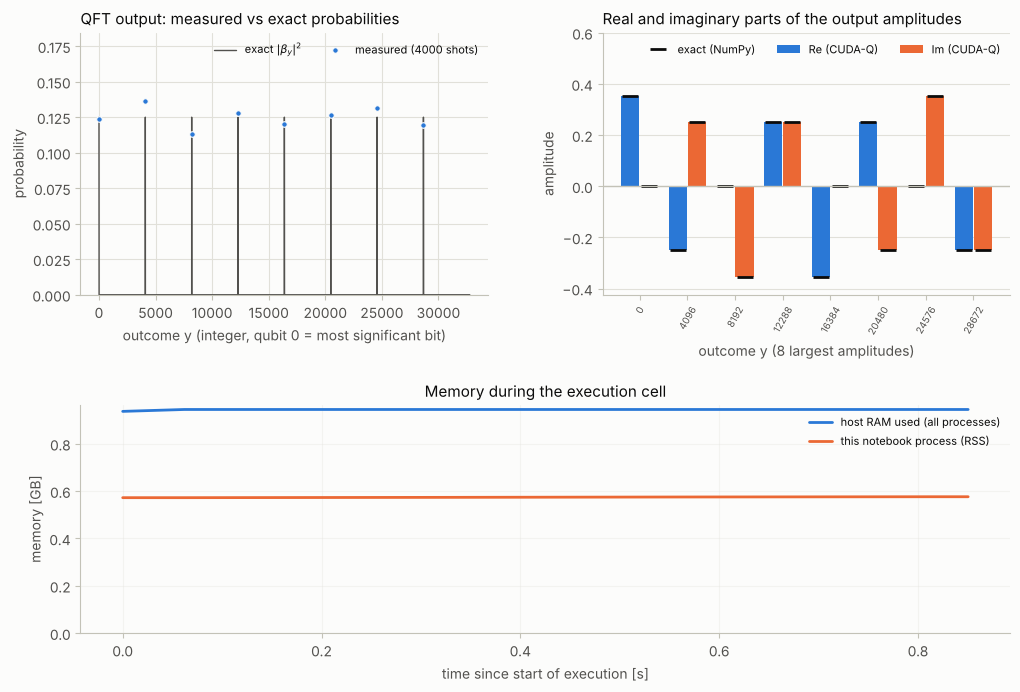

In [10]:
# ---------------------------------------------------------------------------------
# Section 9 - Compare CUDA-Q with the exact Fourier transform
# ---------------------------------------------------------------------------------
fidelity, max_error, tvd = None, None, None
if not execution_ok:
    print("Skipped: the execution cell failed (see the error message above).")
else:
    if quantum_amplitudes is not None:
        overlap = np.vdot(expected_amplitudes, quantum_amplitudes)        # <beta_exact | beta_cudaq>
        fidelity = abs(overlap) ** 2
        max_error = float(np.max(np.abs(quantum_amplitudes - expected_amplitudes)))
        print(f"State fidelity |<exact|CUDA-Q>|^2 : {fidelity:.12f}")
        print(f"Largest amplitude deviation       : {max_error:.3e}\n")
        top = np.argsort(np.abs(quantum_amplitudes))[::-1][:TOP_K]
        top = [int(y) for y in top if abs(quantum_amplitudes[y]) > 1e-9]   # hide numerical-noise amplitudes
        print(f"{'y':>8} {'bitstring':<{N_QUBITS}}  {'Re (CUDA-Q)':>12} {'Im (CUDA-Q)':>12} {'|beta|^2':>10} {'Re (exact)':>11} {'Im (exact)':>11}")
        for y in top:
            a, e = quantum_amplitudes[y], expected_amplitudes[y]
            print(f"{y:>8} {format(int(y), f'0{N_QUBITS}b'):<{N_QUBITS}}  {a.real:>12.6f} {a.imag:>12.6f} "
                  f"{abs(a) ** 2:>10.6f} {e.real:>11.6f} {e.imag:>11.6f}")

    # ---- measured vs expected distribution -------------------------------------------------
    if expected_amplitudes is not None:
        probs = np.abs(expected_amplitudes) ** 2
    elif mode == "periodic":                                           # closed form for large N
        probs = None
        peak_set = {m * (M // int(PERIOD)) for m in range(int(PERIOD))}
    else:
        probs = None
    freq_y = np.array(list(measured.keys()), dtype=np.int64)
    freq_v = np.array(list(measured.values()), dtype=float) / SHOTS
    if probs is not None:
        tvd = 0.5 * (np.abs(freq_v - probs[freq_y]).sum() + (1.0 - probs[freq_y].sum()))  # unseen outcomes add their full P
        print(f"\nTotal variation distance (measured vs exact): {tvd:.4f}")
    elif mode == "periodic":
        on_peaks = sum(c for y, c in measured.items() if y in peak_set) / SHOTS
        print(f"\nFraction of shots on the {PERIOD} expected peaks: {on_peaks:.4f} (exact: 1.0)")
    else:
        print(f"\nUniform expectation P = 1/{M:,}: with {SHOTS} shots nearly every outcome appears at most once.")
    print(f"\nMost frequent measured bitstrings:")
    for bits, c in sorted(counts.items(), key=lambda kv: kv[1], reverse=True)[:min(TOP_K, 10)]:
        y = int(bits, 2)
        if probs is not None:
            exact = f"{probs[y]:.4f}"                                     # exact probability from the FFT
        elif mode == "periodic":
            exact = f"{1 / int(PERIOD):.4f}" if y in peak_set else "0"    # closed-form peak probability
        else:
            exact = f"{1 / M:.2e}"                                        # uniform distribution
        print(f"  {bits}  y={y:>8,}  measured {c / SHOTS:.4f}  exact {exact}")

    # ---- plots -------------------------------------------------------------------------------
    fig = plt.figure(figsize=(12, 7.8))
    grid = fig.add_gridspec(2, 2, height_ratios=[1.15, 1.0], hspace=0.45, wspace=0.28)
    ax_p = fig.add_subplot(grid[0, :] if quantum_amplitudes is None else grid[0, 0])
    if probs is not None and M <= 65536:
        ax_p.plot(np.arange(M), probs, color=INK_SECONDARY, linewidth=1.0, label=r"exact $|\beta_y|^2$")
    elif probs is not None:                                               # very large M: plot the largest values only
        idx = np.sort(np.argsort(probs)[::-1][:4096])
        ax_p.plot(idx, probs[idx], ".", color=INK_SECONDARY, markersize=2, label=r"exact $|\beta_y|^2$ (4096 largest)")
    ax_p.plot(freq_y, freq_v, "o", color=BLUE, markersize=4, markeredgecolor=SURFACE, markeredgewidth=0.8,
              label=f"measured ({SHOTS} shots)")
    ax_p.set_xlabel("outcome y (integer, qubit 0 = most significant bit)")
    ax_p.set_ylabel("probability")
    ax_p.set_title("QFT output: measured vs exact probabilities", loc="left")
    y_top = max(float(np.max(probs)) if probs is not None else 0.0, float(freq_v.max()))
    ax_p.set_ylim(0, y_top * 1.35)                                   # headroom keeps the legend off the data
    ax_p.legend(fontsize=8, loc="upper right", ncol=2)
    if quantum_amplitudes is not None:
        ax_a = fig.add_subplot(grid[0, 1])
        top_sorted = np.array(sorted(top))                                # largest amplitudes, in index order
        positions = np.arange(len(top_sorted))
        ax_a.bar(positions - 0.2, quantum_amplitudes[top_sorted].real, width=0.38, color=BLUE, label="Re (CUDA-Q)")
        ax_a.bar(positions + 0.2, quantum_amplitudes[top_sorted].imag, width=0.38, color=ORANGE, label="Im (CUDA-Q)")
        ax_a.plot(positions - 0.2, expected_amplitudes[top_sorted].real, "_", color=INK, markersize=12, markeredgewidth=2)
        ax_a.plot(positions + 0.2, expected_amplitudes[top_sorted].imag, "_", color=INK, markersize=12,
                  markeredgewidth=2, label="exact (NumPy)")
        ax_a.axhline(0, color=AXIS_COLOR, linewidth=1)
        ax_a.set_xticks(positions, [str(y) for y in top_sorted], rotation=60, fontsize=7)
        ax_a.set_xlabel(f"outcome y ({len(top_sorted)} largest amplitudes)")
        ax_a.set_ylabel("amplitude")
        ax_a.set_title("Real and imaginary parts of the output amplitudes", loc="left")
        a_max = float(np.max(np.abs(np.r_[quantum_amplitudes[top_sorted].real, quantum_amplitudes[top_sorted].imag])))
        ax_a.set_ylim(-1.2 * a_max, 1.7 * a_max)                     # headroom for the legend
        ax_a.legend(fontsize=8, loc="upper right", ncol=3)
        ax_a.grid(axis="x", visible=False)
    ax_m = fig.add_subplot(grid[1, :])
    monitor.plot(ax=ax_m, title="Memory during the execution cell")
    plt.show()

---
## Section 10 - Final benchmark report

                                       FINAL BENCHMARK REPORT                                       
Algorithm                         : Quantum Fourier Transform
Date (UTC)                        : 2026-11-05 22:55:30
CUDA-Q version                    : 0.16.0
Number of qubits                  : 15
Backend (requested -> used)       : auto -> cpu
CUDA-Q target                     : qpp-cpu
Simulation method                 : statevector
Numerical precision               : fp64
Number of shots                   : 4000
Circuit construction time         : 0.0260 s
Compilation time (MLIR + JIT)     : 0.0513 s
Quantum execution time            : 0.3027 s
Sampling run time (execution)     : 0.3316 s
Total wall time of execution cell : 0.7685 s
Timing method                     : CUDA-Q span tracer (first launch)
Peak host RAM used                : 0.94 GB (5.6% of 16.9 GB)
Peak notebook process RSS         : 0.58 GB (baseline 0.57 GB)
Peak GPU memory                   : not available - NVML 

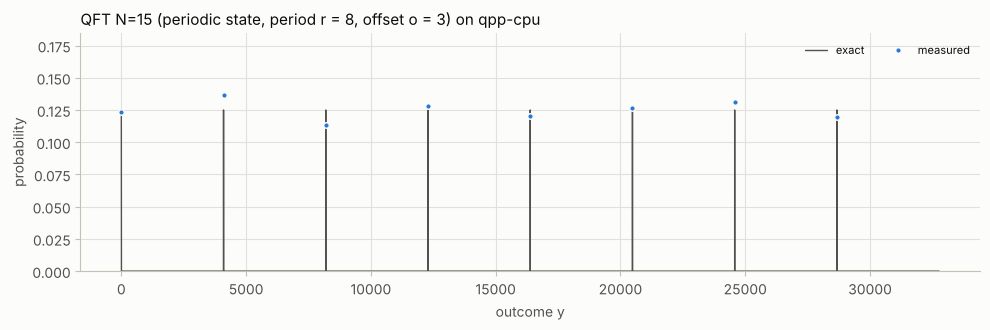

In [11]:
# ---------------------------------------------------------------------------------
# Section 10 - Final benchmark report
# ---------------------------------------------------------------------------------
if not execution_ok:
    print(f"No report: execution failed with {type(execution_error).__name__}: {execution_error}")
else:
    extra = {"Sampling run time (execution)": sampling_time} if state_phases is not None else {}
    report = build_report("Quantum Fourier Transform", backend_cfg, N_QUBITS, SHOTS, phases, memory, extra_times=extra)
    report["Input state"] = description
    report["Gates in the QFT circuit"] = f"{stats.get('gates (excluding measurements)', 'n/a')} (depth {stats.get('depth', 'n/a')})"
    if expected_amplitudes is not None:
        top_y = int(np.argmax(np.abs(expected_amplitudes)))
        report["Expected result"] = (f"exact FFT: {np.count_nonzero(np.abs(expected_amplitudes) ** 2 > 1e-12):,} outcomes with P>0, "
                                     f"largest P = {np.max(np.abs(expected_amplitudes)) ** 2:.4f} at y = {top_y}")
    elif mode == "periodic":
        report["Expected result"] = f"{PERIOD} peaks at multiples of {M // int(PERIOD):,}, P = {1 / int(PERIOD):.4f} each"
    else:
        report["Expected result"] = f"uniform distribution, P(y) = 1/{M:,}"
    best = max(counts.items(), key=lambda kv: kv[1])
    report["Actual result"] = f"{len(measured):,} distinct outcomes; most frequent {best[0]} (y={int(best[0], 2):,}) with {best[1] / SHOTS:.4f}"
    if fidelity is not None:
        report["State fidelity vs exact QFT"] = f"{fidelity:.12f} (max amplitude error {max_error:.2e})"
    if tvd is not None:
        report["Total variation distance (shots)"] = f"{tvd:.4f}"
    elif mode == "periodic":
        report["Fraction of shots on expected peaks"] = f"{on_peaks:.4f}"
    final_fig, ax = plt.subplots(figsize=(10, 3.4))
    if probs is not None and M <= 65536:
        ax.plot(np.arange(M), probs, color=INK_SECONDARY, linewidth=1.0, label="exact")
    elif probs is not None:
        ax.plot(idx, probs[idx], ".", color=INK_SECONDARY, markersize=2, label="exact (largest values)")
    ax.plot(freq_y, freq_v, "o", color=BLUE, markersize=4, markeredgecolor=SURFACE, label="measured")
    ax.set_xlabel("outcome y")
    ax.set_ylabel("probability")
    ax.set_ylim(0, y_top * 1.35)
    ax.set_title(f"QFT N={N_QUBITS} ({description}) on {cudaq.get_target().name}", loc="left")
    ax.legend(fontsize=8, loc="upper right", ncol=2)
    final_fig.tight_layout()
    show_report(report, save=SAVE_REPORT, out_dir=EXPORT_DIR, name="qft_benchmark_report", figure=final_fig)
    plt.show()

---
### Things to try next
* `PERIOD = 6` shows *leakage*: the period does not divide $2^N$, so probability spreads around the ideal peaks
  $m\,2^N/6$ - exactly the situation that Shor's algorithm handles with continued fractions.
* `INITIAL_STATE = "basis"` gives a perfectly flat distribution: all information is in the phases (see the
  amplitude table), which is why a single QFT measurement cannot reveal a basis state.
* Increase `N_QUBITS` to 25-30 on a GPU, or to 40+ with `SIMULATION_METHOD = "mps"` - the QFT of the default
  periodic input is only weakly entangled, so the matrix-product-state simulator handles it easily.